# TP Deep QLearning


### **Binôme :** Ahdi BEN MAAOUIA & Abderrahim BEN MOHA


Dans ce TP, l'objectif est d'implémenter un agent apprenant à faire atterir un vaisseau sur la lune avec l'algorithme Deep Q-Network. Pour cela vous allez utiliser [PyTorch](https://pytorch.org/) et [Gymnasium](https://gymnasium.farama.org/). 

<img src='img/lunarlander.png'  width=500px>

# 1. Consignes

> Compléter ce notebook et les différents fichiers python associés. 
> 
> Répondre aux questions.


> Le code doit être fonctionnel avec l'environnement virtuel du TP. Si d'autres packages que ceux présents dans l'environnement virtuel créé au départ sont nécessaires, vous devez ajouter à votre dépôt un fichier `environnement.yaml` qui est un export de votre environnement virtuel. Ce fichier est obtenu avec la commande suivante:  ```conda env export > environnement.yaml```



# 2. Import des packages

In [1]:
import gymnasium as gym
import random
import torch
import numpy as np
from collections import deque
import matplotlib.pyplot as plt
%matplotlib inline
%load_ext autoreload

def init_seed(seedval):
    torch.manual_seed(seedval)
    np.random.seed(seedval)
    random.seed(seedval)

# 3. Gymnasium

En apprentissage par renforcement, il y a deux concepts fondamentaux : l’agent et l’environnement.
- L’agent est l’entité apprenante qui observe l’environnement et agit sur celui-ci selon les actions disponibles. Son objectif est de maximiser la récompense cumulée qu’il recoit de l’environnement avec lequel il interagit.
- L'agent interagit avec l'environnement à travers la boucle de perception/action ce qui nécessite de définir :
    - Un espace d’action.
    - Un espace d’état (ou observation).
    - Une fonction de récompense.
  
[Gymnasium](https://gymnasium.farama.org/) propose une interface open source unifiée entre un agent et un environnement.
- [Gymnasium](https://gymnasium.farama.org/) propose un ensemble d'environnements pour des tâches d'apprentissage par renforcement. La plupart des environnements ont leur code source disponible sur [GitHub](https://github.com/Farama-Foundation/Gymnasium/tree/main/gymnasium/envs). De nouveaux environnements peuvent aussi être créés à condition qu'ils soient compatibles avec l'interface. 
- Grâce à l'interface unifiée, il est possible de définir indépendamment un agent de l’environnement avec lequel il interagit (et inversement). 
- Lorsque certains pré-traitements sont nécessaires sur les actions, observations, récompenses, ... il est possible d’encapsuler l’environnement dans un **wrapper**, celui-ci se chargera du pré-traitement. 




>  <span style="color:green">Documentation de Gymnasium</span>: [utilisation basique](https://gymnasium.farama.org/content/basic_usage/), [API pour les environnements](https://gymnasium.farama.org/api/env/), ...




##  3.1 - Caractéristiques de l'environnement LunarLander

Dans ce TP, nous allons implémenter un agent qui interagira avec l'environnement **LunarLander**, présenté  [ici](https://gymnasium.farama.org/environments/box2d/lunar_lander/) et le code source est [ici](https://github.com/openai/gym/blob/master/gym/envs/box2d/lunar_lander.py). 2 versions de LunarLander existent: avec des actions discrètes ou des actions continues.

> <span style="color:green">Quelle version de LunarLander choisir pour utiliser le DQN ? Pourquoi ? 

<span style="color: white"> On doit prendre la version de LunarLander avec des actions **discrètes**. Le principe du DQN repose sur le fait de pouvoir attribuer une Q-valeur à une action donnée dans un état donné. Il faut donc un nombre fini d'actions à tester dans chaque état afin de pouvoir calculer le maximum et mettre à jour les poids du réseau de neurones. Ainsi, on pourra choisir dans notre politique l'action qui a la Q-valeur maximale.


Il existe plusieurs fonctions clés pour interagir avec un environnement Gymnasium ( [utilisation basique](https://gymnasium.farama.org/introduction/basic_usage/) et [API](https://gymnasium.farama.org/api/env/)).


> <span style="color:green">Compléter la cellule de code ci-dessous pour afficher:
> 
> - **les dimensions pour les espaces d'états et d'actions** de l'environnement `LunarLander`.
> - les bornes min et max pour les dimensions de l'état
> - un échantillon pris au hasard dans chaque espace. 

In [2]:
env = gym.make("LunarLander-v3")

# Les dimensions pour les espaces d'états et d'actions
print(f"Dimension de l'espace d'états : {env.observation_space.shape[0]}")
print(f"Nombre d'actions possibles (discrètes) : {env.action_space.n}")

# Les bornes min et max pour les dimensions de l'état
print(f"Bornes minimales : \n{env.observation_space.low}")
print(f"Bornes maximales : \n{env.observation_space.high}")

# Un échantillon pris au hasard dans chaque espace
print(f"Échantillon d'état : \n{env.observation_space.sample()}")
print(f"Échantillon d'action : {env.action_space.sample()}")

env.close()

Dimension de l'espace d'états : 8
Nombre d'actions possibles (discrètes) : 4
Bornes minimales : 
[ -2.5        -2.5       -10.        -10.         -6.2831855 -10.
  -0.         -0.       ]
Bornes maximales : 
[ 2.5        2.5       10.        10.         6.2831855 10.
  1.         1.       ]
Échantillon d'état : 
[ 2.4321818  -0.5213982  -8.504641    7.492978    3.750152   -6.6859074
  0.8759032   0.17197718]
Échantillon d'action : 3


> <span style="color:green">A quoi correspond dans le cas du LunarLander une terminaison d'un épisode avec *terminated* à True ? 

<span style="color: white"> Dans le cas du LunarLander, le flag *terminated = True* indique que l'épisode a atteint un état terminal physique (une fin de partie naturelle). Cela se produit dans trois situations :
> 1. **L'atterrissage réussi :** Le module s'est posé en douceur et est resté immobile sur la zone cible entre les deux drapeaux.
> 2. **Le crash :** Le corps principal du vaisseau a percuté le sol ou le module s'est écrasé suite à une vitesse d'impact trop élevée.
> 3. **La sortie de zone :** Le vaisseau est sorti des limites de l'écran.

## 3.2 Interaction et affichage de l'environnement sur un épisode

> <span style="color:green">Exécuter une instance de l'environnement `LunarLander` pendant un épisode avec des **actions aléatoires**. Afficher l'environnement à chaque pas pour visualiser le comportement du vaisseau. A la fin de l'épisode, afficher la somme des récompenses obtenues sur l'épisode. </span>



In [3]:
import time

env = gym.make("LunarLander-v3", render_mode="human")

observation, info = env.reset()

terminated = False
truncated = False
total_reward = 0

# Boucle pricipale
while not (terminated or truncated):
    # Sélection d'une action aléatoire
    action = env.action_space.sample()  
    
    # Exécution de l'action
    observation, reward, terminated, truncated, info = env.step(action)
    
    # Accumulation de la récompense
    total_reward += reward

    time.sleep(0.03)

# Affichage du score final de l'épisode
print(f"Fin de l'épisode ! Score total (Somme des récompenses) : {total_reward:.2f}")

time.sleep(2)
env.close()

Fin de l'épisode ! Score total (Somme des récompenses) : -153.79


# 4. Agent simple (sans apprentissage)

Vous devez maintenant implémenter un **agent simple** qui utilise une **Q fonction paramétrée** (réseau de neurones) pour choisir ses actions selon une stratégie $\epsilon$-greedy (mais sans apprentissage pour l'instant).

> <span style="color:green">- Quels éléments seront en entrée du NN ? En sortie ? Quelle sera la dimension de l'entrée ? De la sortie ? </span>

<span style="color: white">On aura 8 entrées pour le réseau de neurone pour chaque dimension de l'environnement et 4 sorties pour les Q-valeurs estimées pour chaque action possible

> <span style="color:green">- Quelle fonction d'activation sera utilisée sur la dernière couche du réseau ? Pourquoi ? </span>

<span style="color: white">On aura aucune fonction d'activation pour la dernière couche du réseau car les sorties du réseau ne sont pas des probabilités ou des classes, mais des estimations de récompenses cumulées futures. Ces valeurs peuvent être théoriquement n'importe quel nombre réel. Appliquer une fonction d'activation contraindrait ou fausserait la prédiction de ces scores réels.

- définir l'architecture du réseau de neurones en complétant `QNN.py`. Ce réseau va approximer la Q-fonction comme dans DQN (pour l'instant, les poids du réseau ne seront pas mis à jour, le réseau est uniquement utilisé en prédiction).

- définir un agent simple en complétant `agentsimple.py`: il utilisera la prédiction du réseau de neurones pour choisir ses actions selon une stratégie d’exploration $\epsilon$-greedy.

- utiliser cet agent sur plusieurs épisodes dans `LunarLander`. Vous utiliserez une décroissance de l'exploration, i.e. que $\epsilon$ va décroitre à chaque épisode, en démarrant à une valeur élevée (beaucoup d'exploration) et avec une borne minimum. Ainsi, au premier épisode, $\epsilon=\epsilon_{start}$, et à chaque épisode, $\epsilon=max(\epsilon_{end}, \epsilon_{decay}*\epsilon)$. Par exemple sur 1000 épisodes, les valeurs peuvent être $\epsilon_{start} = 1.0$, $\epsilon_{end} = 0.01$ et $\epsilon_{decay} = 0.995$.

- proposer un tracé de la somme des récompenses obtenues par épisode (vous pouvez utiliser le fichier `utils.py`, le wrapper [RecordEpisodeStatistics](https://gymnasium.farama.org/api/wrappers/misc_wrappers/#gymnasium.wrappers.RecordEpisodeStatistics ),  ...).


In [4]:
#Reload all modules every time before executing the Python code typed
%autoreload 2
# import depuis un fichier python local 
from QNN import QNN 
from agentsimple import AgentSimple
import utils

Épisode 20/1000 | Score: -381.40 | Epsilon: 0.905
Épisode 40/1000 | Score: -312.76 | Epsilon: 0.818
Épisode 60/1000 | Score: -28.92 | Epsilon: 0.740
Épisode 80/1000 | Score: -454.54 | Epsilon: 0.670
Épisode 100/1000 | Score: -95.47 | Epsilon: 0.606
Épisode 120/1000 | Score: -437.97 | Epsilon: 0.548
Épisode 140/1000 | Score: -276.27 | Epsilon: 0.496
Épisode 160/1000 | Score: -337.55 | Epsilon: 0.448
Épisode 180/1000 | Score: -254.27 | Epsilon: 0.406
Épisode 200/1000 | Score: -455.34 | Epsilon: 0.367
Épisode 220/1000 | Score: -752.88 | Epsilon: 0.332
Épisode 240/1000 | Score: -786.49 | Epsilon: 0.300
Épisode 260/1000 | Score: -562.90 | Epsilon: 0.272
Épisode 280/1000 | Score: -660.34 | Epsilon: 0.246
Épisode 300/1000 | Score: -562.62 | Epsilon: 0.222
Épisode 320/1000 | Score: -568.19 | Epsilon: 0.201
Épisode 340/1000 | Score: -338.98 | Epsilon: 0.182
Épisode 360/1000 | Score: -580.29 | Epsilon: 0.165
Épisode 380/1000 | Score: -418.62 | Epsilon: 0.149
Épisode 400/1000 | Score: -425.17 | E

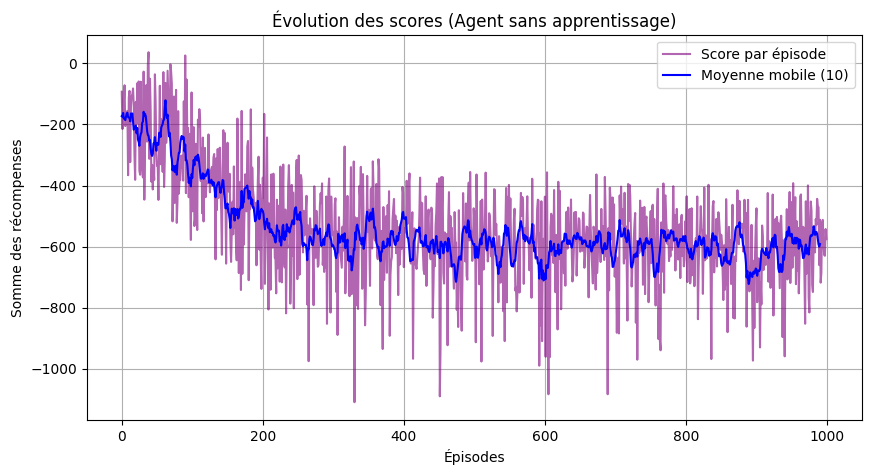

In [5]:
import gymnasium as gym
import matplotlib.pyplot as plt

# Création de l'environnement avec statistiques intégrées
env = gym.make("LunarLander-v3")
env = gym.wrappers.RecordEpisodeStatistics(env)

# Paramètres de l'agent et d'exploration
dim_entree = env.observation_space.shape[0]
dim_sortie = env.action_space.n
agent = AgentSimple(dim_entree, dim_sortie)

num_episodes = 1000
eps_start = 1.0
eps_end = 0.01
eps_decay = 0.995
eps = eps_start

scores = []

# Boucle principale par épisode
for episode in range(num_episodes):
    observation, info = env.reset()
    terminated = False
    truncated = False
    
    while not (terminated or truncated):
        action = agent.action_egreedy(observation, eps)
        
        observation, reward, terminated, truncated, info = env.step(action)
        
    # Récupération du score cumulé de l'épisode
    score_episode = info["episode"]["r"]
    scores.append(score_episode)
    
    # Décroissance de epsilon après chaque épisode
    eps = max(eps_end, eps_decay * eps)
    
    # Affichage régulier du suivi
    if (episode + 1) % 20 == 0:
        print(f"Épisode {episode+1}/{num_episodes} | Score: {score_episode:.2f} | Epsilon: {eps:.3f}")

env.close()

# Tracé graphique des résultats
plt.figure(figsize=(10, 5))
plt.plot(scores, label="Score par épisode", color="purple", alpha=0.6)
plt.plot(np.convolve(scores, np.ones(10)/10, mode='valid'), label="Moyenne mobile (10)", color="blue")
plt.title("Évolution des scores (Agent sans apprentissage)")
plt.xlabel("Épisodes")
plt.ylabel("Somme des récompenses")
plt.legend()
plt.grid(True)
plt.show()

# 5. Deep QLearning avec Replay Buffer

L'algorithme (sans réseau cible) est donné ci-dessous:

<img src='img/algodqnv2.png'  width=700px>

- La phase d'**interaction** avec l'environnement (sans apprentissage): phase pendant laquelle l'agent stocke en mémoire toutes les transitions rencontrées. Une transition est un tuple `(état,action,état_suivant,récompense,fin_episode)`. La mémoire (ou buffer) a une taille maximale; lorsqu’elle est dépassée, les nouvelles transitions remplacent les plus anciennes. 

- La phase d'**apprentissage** permet de mettre à jour les paramètres de la fonction *Q* à partir d'échantillons de transitions (minibatch, de taille $d=64$ par exemple) présentes dans la mémoire. La phase d'apprentissage est réalisée tous les `t` pas (ou actions) dans l'environnement (par ex. $t=4$).

- La classe `ReplayBuffer` du fichier `replaybuffer.py` permet de stocker des transitions dans une mémoire et de récupérer des minibatch de transitions.

Vous devez implémenter l'algorithme du **Deep QLearning avec ReplayBuffer** donné ci-dessus.

Remarque: 
- vous n'utiliserez pas de réseau cible (*target network*) pour l'instant.
- Pour l'optimizer, SGD et [Adam](https://machinelearningmastery.com/adam-optimization-algorithm-for-deep-learning/) sont particulièrement adaptés. 
- Dans la phase d'apprentissage, les éléments récupérés dans un minibatch  sont des tenseurs de taille $d \times dim\_element$. Vous devez dans cette phase faire des calculs tensoriel directement (et pas de boucle for sur $d$ !)
- Voici aussi des liens vers différentes fonctions de PyTorch qui pourraient vous être utiles: [unsqueeze](https://pytorch.org/docs/stable/generated/torch.unsqueeze.html), [gather](https://pytorch.org/docs/stable/generated/torch.gather.html)

> <span style="color:green">Compléter la classe `AgentDQN`</span> 
>
> <span style="color:green">Implémenter l'algorithme dans la fonction *dqnalgo* ci-dessous.  </span> 

In [6]:
#Reload all modules every time before executing the Python code typed
%autoreload 2
from replaybuffer import ReplayBuffer
from agentdqn import AgentDQN

In [7]:
#TODO

def dqnalgo(env, num_episodes=500, eps_start=1.0, eps_end=0.01, eps_decay=0.995, learn_step=4):
    """
        Retourne la somme des recompenses par épisode
    """
    dim_etat = env.observation_space.shape[0]
    dim_action = env.action_space.n
    
    agent = AgentDQN(dim_etat, dim_action)
    scores = []
    eps = eps_start
    t_step = 0
    
    for episode in range(num_episodes):
        observation, info = env.reset()
        terminated = False
        truncated = False
        
        while not (terminated or truncated):
            # Sélection de l'action é-greedy
            action = agent.action_egreedy(observation, eps)
            
            # Exécution de l'action
            observation_suivante, reward, terminated, truncated, info = env.step(action)
            
            # Stockage de la transition dans le buffer
            agent.phase_interaction(observation, action, reward, observation_suivante, terminated)
            
            # Transition vers l'état suivant
            observation = observation_suivante
            t_step += 1
            
            # Apprentissage toutes les 'learn_step' étapes
            if t_step % learn_step == 0:
                agent.phase_apprentissage()
                
        # Récupération du score cumulé
        score_episode = info["episode"]["r"]
        scores.append(score_episode)
        
        # Décroissance de l'exploration
        eps = max(eps_end, eps_decay * eps)
        
        if (episode + 1) % 20 == 0:
            moyenne = np.mean(scores[-20:])
            print(f"Épisode {episode+1}/{num_episodes} | Moyenne (20 dern.): {moyenne:.2f} | Epsilon: {eps:.3f}")
            
    return scores

    

>
> <span style="color:green">Utiliser cet agent sur plusieurs épisodes dans l'environnement `LunarLander`. Vous proposerez un tracé de la somme des récompenses obtenues par épisode (vous pouvez utiliser `utils.py`).</span> 


Début de l'entraînement du DQN...
Épisode 20/400 | Moyenne (20 dern.): -209.26 | Epsilon: 0.852
Épisode 40/400 | Moyenne (20 dern.): -159.27 | Epsilon: 0.725
Épisode 60/400 | Moyenne (20 dern.): -112.39 | Epsilon: 0.618
Épisode 80/400 | Moyenne (20 dern.): -111.35 | Epsilon: 0.526
Épisode 100/400 | Moyenne (20 dern.): -114.10 | Epsilon: 0.448
Épisode 120/400 | Moyenne (20 dern.): -189.15 | Epsilon: 0.381
Épisode 140/400 | Moyenne (20 dern.): -71.46 | Epsilon: 0.325
Épisode 160/400 | Moyenne (20 dern.): 2.31 | Epsilon: 0.277
Épisode 180/400 | Moyenne (20 dern.): 65.93 | Epsilon: 0.236
Épisode 200/400 | Moyenne (20 dern.): 11.64 | Epsilon: 0.201
Épisode 220/400 | Moyenne (20 dern.): 44.17 | Epsilon: 0.171
Épisode 240/400 | Moyenne (20 dern.): 105.99 | Epsilon: 0.145
Épisode 260/400 | Moyenne (20 dern.): 58.43 | Epsilon: 0.124
Épisode 280/400 | Moyenne (20 dern.): -15.44 | Epsilon: 0.106
Épisode 300/400 | Moyenne (20 dern.): 5.61 | Epsilon: 0.090
Épisode 320/400 | Moyenne (20 dern.): 14.8

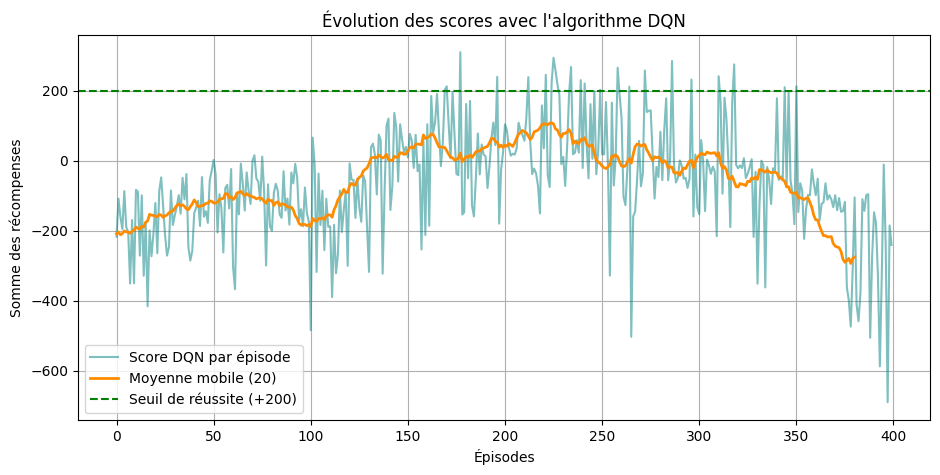

In [9]:
import gymnasium as gym
import matplotlib.pyplot as plt
import numpy as np

# Création et wrapping de l'environnement
env = gym.make("LunarLander-v3")
env = gym.wrappers.RecordEpisodeStatistics(env)

# Lancement de l'algorithme DQN 
print("Début de l'entraînement du DQN...")
scores_dqn = dqnalgo(
    env=env, 
    num_episodes=400, 
    eps_start=1.0, 
    eps_end=0.01, 
    eps_decay=0.992, 
    learn_step=4
)
env.close()

# Tracé des récompenses obtenues par épisode
plt.figure(figsize=(11, 5))
plt.plot(scores_dqn, label="Score DQN par épisode", color="teal", alpha=0.5)

if len(scores_dqn) >= 20:
    moyenne_mobile = np.convolve(scores_dqn, np.ones(20)/20, mode='valid')
    plt.plot(moyenne_mobile, label="Moyenne mobile (20)", color="darkorange", linewidth=2)

plt.title("Évolution des scores avec l'algorithme DQN")
plt.xlabel("Épisodes")
plt.ylabel("Somme des récompenses")
plt.axhline(y=200, color="green", linestyle="--", label="Seuil de réussite (+200)")
plt.legend()
plt.grid(True)
plt.show()

> <span style="color:green">Faites maintenant une moyenne sur différents seed, avec un apprentissage par seed, et tracer le résultat (somme des récompenses par épisodes) moyenné sur ces seed. Vous utiliserez `init_seed()` et pouvez utiliser `utils.py`.</span> </span> 

Lancement de l'évaluation adaptative sur 3 seeds...

--- DÉMARRAGE DU SEED 42 (1/3) ---
Épisode 20/400 | Moyenne (20 dern.): -167.80 | Epsilon: 0.852
Épisode 40/400 | Moyenne (20 dern.): -132.75 | Epsilon: 0.725
Épisode 60/400 | Moyenne (20 dern.): -131.19 | Epsilon: 0.618
Épisode 80/400 | Moyenne (20 dern.): -80.68 | Epsilon: 0.526
Épisode 100/400 | Moyenne (20 dern.): -109.35 | Epsilon: 0.448
Épisode 120/400 | Moyenne (20 dern.): -78.29 | Epsilon: 0.381
Épisode 140/400 | Moyenne (20 dern.): -18.36 | Epsilon: 0.325
Épisode 160/400 | Moyenne (20 dern.): -8.49 | Epsilon: 0.277
Épisode 180/400 | Moyenne (20 dern.): -21.51 | Epsilon: 0.236
Épisode 200/400 | Moyenne (20 dern.): 48.21 | Epsilon: 0.201
Épisode 220/400 | Moyenne (20 dern.): 133.01 | Epsilon: 0.171
Épisode 240/400 | Moyenne (20 dern.): 52.96 | Epsilon: 0.145
Épisode 260/400 | Moyenne (20 dern.): 140.33 | Epsilon: 0.124
Épisode 280/400 | Moyenne (20 dern.): 210.79 | Epsilon: 0.106
Épisode 300/400 | Moyenne (20 dern.): 209.54 | 

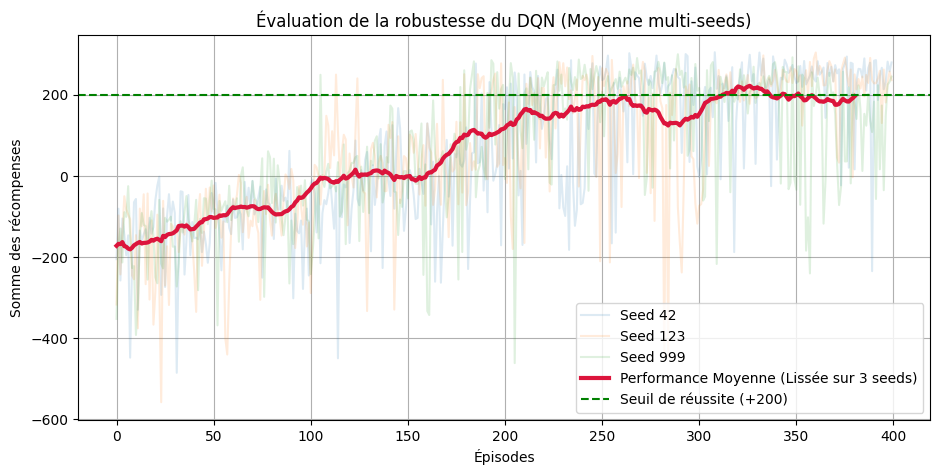

In [10]:
import gymnasium as gym
import matplotlib.pyplot as plt
import numpy as np
import random
import torch

# Fonction pour fixer les seeds
def init_seed(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed(seed)

# Paramètres de l'expérience
seeds = [42, 123, 999]
num_episodes = 400
toutes_les_courbes = []

print(f"Lancement de l'évaluation adaptative sur {len(seeds)} seeds...")

# Boucle principale sur les différents seeds
for i, seed in enumerate(seeds):
    print(f"\n--- DÉMARRAGE DU SEED {seed} ({i+1}/{len(seeds)}) ---")
    
    # On fixe la graine aléatoire globale
    init_seed(seed)
    
    # On crée l'environnement en lui passant aussi le seed pour Gymnasium
    env = gym.make("LunarLander-v3")
    env.action_space.seed(seed)
    env = gym.wrappers.RecordEpisodeStatistics(env)
    
    # Lancement de l'algorithme
    scores_seed = dqnalgo(
        env=env, 
        num_episodes=num_episodes, 
        eps_start=1.0, 
        eps_end=0.01, 
        eps_decay=0.992, 
        learn_step=4
    )
    env.close()
    
    # On sauvegarde la courbe de ce run
    toutes_les_courbes.append(scores_seed)

# Calcul de la courbe moyenne
matrice_scores = np.array(toutes_les_courbes)
courbe_moyenne_brute = np.mean(matrice_scores, axis=0)

# Tracé graphique final
plt.figure(figsize=(11, 5))

for i, seed in enumerate(seeds):
    plt.plot(toutes_les_courbes[i], alpha=0.15, label=f"Seed {seed}")

# On trace la courbe moyenne lissée en gras
moyenne_mobile_finale = np.convolve(courbe_moyenne_brute, np.ones(20)/20, mode='valid')
plt.plot(moyenne_mobile_finale, label="Performance Moyenne (Lissée sur 3 seeds)", color="crimson", linewidth=3)

plt.title("Évaluation de la robustesse du DQN (Moyenne multi-seeds)")
plt.xlabel("Épisodes")
plt.ylabel("Somme des récompenses")
plt.axhline(y=200, color="green", linestyle="--", label="Seuil de réussite (+200)")
plt.legend()
plt.grid(True)
plt.show()

# 6. Deep QLearning avec réseau cible

Il se peut que votre agent précédent apprenne des comportements intéressants mais qu’ils soient très instables. On va maintenant ajouter un réseau cible pour l'améliorer.

> <span style="color:green"> Quelle est la cause des instabilités de l'algorithme précédent ? Pourquoi le réseau cible améliore ces instabilités ?</span>

<span style="color: white">Dans le DQN basique, le même réseau de neurones est utilisé à la fois pour prédire la valeur actuelle et pour calculer la cible de Bellman. À chaque mise à jour des poids, la cible change immédiatement. C'est le problème de la cible mouvante vu dans le cours.
Le réseau cible est une copie du réseau principal dont les poids sont "figés" pendant un certain nombre d'étapes. En utilisant ce réseau stable pour calculer la cible, on stabilise temporairement l'objectif à atteindre, ce qui rapproche le problème d'un apprentissage supervisé standard. Les gradients s'égarent moins et l'apprentissage devient beaucoup plus robuste et fluide.

L'algorithme DQN (avec réseau cible) est donné ci-dessous:

<img src='img/DQNcible.png'  width=500px>

Le réseau cible sera mis à jour toutes les N étapes d'apprentissage (300 par exemple si $t=4$) en recopiant entièrement le réseau de neurone original dans le duplicat.

Pour copier des poids d'un réseau de neurone vers un autre, la méthode `copy_` peut être appelée sur les paramètres:

`for param_duplicat, param_source in zip(model_duplicat.parameters(), model_source.parameters()):`
           
`param_duplicat.data.copy_(param_source.data)`

> <span style="color:green"> Compléter la classe `AgentDQNCible` pour implémenter un agent apprenant avec DQN (deep QLearning et *target network*).</span> 





> <span style="color:green">Utiliser cet agent **dans l'algorithme dqnalgo précédent**. Vous proposerez un tracé de la somme des récompenses obtenues par épisode sur plusieurs seed.</span> 

Début de l'entraînement DQN avec Réseau Cible...

--- RUN SEED 42 ---


Épisode 40/700 | Moyenne (20 dern.): -166.35 | Epsilon: 0.725
Épisode 80/700 | Moyenne (20 dern.): -130.91 | Epsilon: 0.526
Épisode 120/700 | Moyenne (20 dern.): -118.96 | Epsilon: 0.381
Épisode 160/700 | Moyenne (20 dern.): -17.36 | Epsilon: 0.277
Épisode 200/700 | Moyenne (20 dern.): 105.66 | Epsilon: 0.201
Épisode 240/700 | Moyenne (20 dern.): -5.81 | Epsilon: 0.145
Épisode 280/700 | Moyenne (20 dern.): 138.34 | Epsilon: 0.106
Épisode 320/700 | Moyenne (20 dern.): 127.07 | Epsilon: 0.077
Épisode 360/700 | Moyenne (20 dern.): 148.66 | Epsilon: 0.055
Épisode 400/700 | Moyenne (20 dern.): 184.56 | Epsilon: 0.040
Épisode 440/700 | Moyenne (20 dern.): 220.24 | Epsilon: 0.029
Épisode 480/700 | Moyenne (20 dern.): 233.54 | Epsilon: 0.021
Épisode 520/700 | Moyenne (20 dern.): 228.72 | Epsilon: 0.015
Épisode 560/700 | Moyenne (20 dern.): 219.43 | Epsilon: 0.011
Épisode 600/700 | Moyenne (20 dern.): 125.34 | Epsilon: 0.010
Épisode 640/700 | Moyenne (20 dern.): 210.80 | Epsilon: 0.010
Épisode 

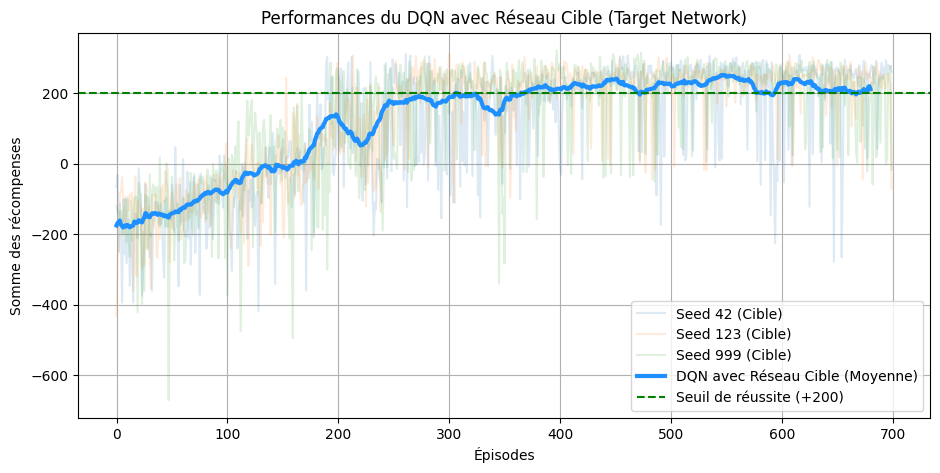

In [13]:
from agentdqncible import AgentDQNCible

import gymnasium as gym
import matplotlib.pyplot as plt
import numpy as np

def run_dqn_cible(env, num_episodes=700, eps_start=1.0, eps_end=0.01, eps_decay=0.992, learn_step=4):
    dim_etat = env.observation_space.shape[0]
    dim_action = env.action_space.n
    
    # On instancie l'agent avec le Target Network configuré
    agent = AgentDQNCible(dim_etat, dim_action, target_update_freq=300)
    scores = []
    eps = eps_start
    t_step = 0
    
    for episode in range(num_episodes):
        observation, info = env.reset()
        terminated = False
        truncated = False
        
        while not (terminated or truncated):
            action = agent.action_egreedy(observation, eps)
            observation_suivante, reward, terminated, truncated, info = env.step(action)
            agent.phase_interaction(observation, action, reward, observation_suivante, terminated)
            
            observation = observation_suivante
            t_step += 1
            
            if t_step % learn_step == 0:
                agent.phase_apprentissage()
                
        score_episode = info["episode"]["r"]
        scores.append(score_episode)
        eps = max(eps_end, eps_decay * eps)
        
        if (episode + 1) % 40 == 0:
            moyenne = np.mean(scores[-20:])
            print(f"Épisode {episode+1}/{num_episodes} | Moyenne (20 dern.): {moyenne:.2f} | Epsilon: {eps:.3f}")
            
    return scores

seeds = [42, 123, 999]
toutes_les_courbes_cible = []

print("Début de l'entraînement DQN avec Réseau Cible...")
for seed in seeds:
    print(f"\n--- RUN SEED {seed} ---")
    init_seed(seed)
    
    env = gym.make("LunarLander-v3")
    env.action_space.seed(seed)
    env = gym.wrappers.RecordEpisodeStatistics(env)
    
    scores = run_dqn_cible(env, num_episodes=700)
    env.close()
    toutes_les_courbes_cible.append(scores)

# Calcul des moyennes
matrice_scores_cible = np.array(toutes_les_courbes_cible)
courbe_moyenne_cible = np.mean(matrice_scores_cible, axis=0)
moyenne_mobile_cible = np.convolve(courbe_moyenne_cible, np.ones(20)/20, mode='valid')

# Tracé Graphique
plt.figure(figsize=(11, 5))
for i, seed in enumerate(seeds):
    plt.plot(toutes_les_courbes_cible[i], alpha=0.15, label=f"Seed {seed} (Cible)")

plt.plot(moyenne_mobile_cible, label="DQN avec Réseau Cible (Moyenne)", color="dodgerblue", linewidth=3)
plt.axhline(y=200, color="green", linestyle="--", label="Seuil de réussite (+200)")
plt.title("Performances du DQN avec Réseau Cible (Target Network)")
plt.xlabel("Épisodes")
plt.ylabel("Somme des récompenses")
plt.legend()
plt.grid(True)
plt.show()

# 6. Sauvegarde d'un agent

> <span style="color:green"> Sauvegarder un agent qui a correctement appris dans un fichier 'monAgentDQN.pth'. Vous préciserez ci-dessous les hyperparamètres utilisés pour cet agent. </span> 

> <span>Hyperparamètres de l'agent :</span>
> * **Architecture du QNN :** Perceptron Multicouche (MLP) avec 2 couches cachées de 64 neurones chacune. Activations ReLU.
> * **Taille du lot (Batch Size) :** $d = 64$
> * **Taille de la mémoire (Replay Buffer) :** $N = 10 000$
> * **Facteur d'atténuation (Gamma) :** $\gamma = 0.99$
> * **Taux d'apprentissage (Learning Rate) :** $lr = 1e-3$ (Optimiseur Adam)
> * **Fréquence d'apprentissage (Learn Step) :** Toutes les $t = 4$ étapes.
> * **Fréquence de mise à jour de la cible ($C$) :** Toutes les 300 étapes d'apprentissage.
> * **Stratégie $\epsilon$-greedy :** Décroissance exponentielle de $\epsilon_{start} = 1.0$ à $\epsilon_{end} = 0.01$ avec un coefficient $\epsilon_{decay} = 0.992$ sur 400 épisodes.

In [15]:
#Exemple de code pour sauvegarde d'un réseau
#savedfile = 'checkpoint.pth'
#torch.save(agent.network.state_dict(), savedfile)

#Exemple de code pour chargement d'un reseau sauvegarde
#state_dict = torch.load(savedfile)
#agent.network.load_state_dict(state_dict)

> <span style="color:green"> Proposer un code ci-dessous qui charge un agent ayant correctement appris, et visualise un épisode de cet agent en mode glouton. </span> 


In [ ]:
# Configuration d'un run unique pour la sauvegarde
init_seed(42)
env_sauve = gym.make("LunarLander-v3")
env_sauve = gym.wrappers.RecordEpisodeStatistics(env_sauve)

dim_etat = env_sauve.observation_space.shape[0]
dim_action = env_sauve.action_space.n

# On crée l'agent dans le scope global
agent_a_sauver = AgentDQNCible(dim_etat, dim_action, target_update_freq=300)

num_episodes = 450
eps = 1.0
t_step = 0

print("Lancement de l'entraînement pour générer le fichier de sauvegarde...")

for episode in range(num_episodes):
    observation, info = env_sauve.reset()
    terminated = False
    truncated = False
    
    while not (terminated or truncated):
        action = agent_a_sauver.action_egreedy(observation, eps)
        observation_suivante, reward, terminated, truncated, info = env_sauve.step(action)
        agent_a_sauver.phase_interaction(observation, action, reward, observation_suivante, terminated)
        
        observation = observation_suivante
        t_step += 1
        
        if t_step % 4 == 0:
            agent_a_sauver.phase_apprentissage()
            
    eps = max(0.01, 0.992 * eps)
    
    if (episode + 1) % 50 == 0:
        print(f"Épisode {episode+1}/{num_episodes} | Epsilon: {eps:.3f}")

# Sauvegarde physique du fichier sur le disque
torch.save(agent_a_sauver.q_network.state_dict(), 'monAgentDQN.pth')
print("\nLe fichier 'monAgentDQN.pth' a été créé avec succès dans ton dossier de TP.")

env_sauve.close()

Lancement de l'entraînement express pour générer le fichier de sauvegarde...
Épisode 50/450 | Epsilon: 0.669
Épisode 100/450 | Epsilon: 0.448
Épisode 150/450 | Epsilon: 0.300
Épisode 200/450 | Epsilon: 0.201
Épisode 250/450 | Epsilon: 0.134
Épisode 300/450 | Epsilon: 0.090
Épisode 350/450 | Epsilon: 0.060
Épisode 400/450 | Epsilon: 0.040
Épisode 450/450 | Epsilon: 0.027

Félicitations ! Le fichier 'monAgentDQN.pth' a été créé avec succès dans ton dossier de TP.


In [ ]:
import time
import torch
import gymnasium as gym
from agentdqncible import AgentDQNCible

env = gym.make("LunarLander-v3", render_mode="human")

# Récréer l'architecture de l'agent
dim_etat = env.observation_space.shape[0]
dim_action = env.action_space.n
agent_teste = AgentDQNCible(dim_etat, dim_action)

# Charger les poids du fichier sauvegardé
saved_file = 'monAgentDQN.pth'
state_dict = torch.load(saved_file, map_location=torch.device('cpu'))
agent_teste.q_network.load_state_dict(state_dict)

# Passer le réseau en mode évaluation
agent_teste.q_network.eval()

print("Début de l'épisode de démonstration...")

# Lancement de l'épisode graphique
observation, info = env.reset()
terminated = False
truncated = False
total_reward = 0

while not (terminated or truncated):
    action = agent_teste.action_egreedy(observation, eps=0.0)
    
    observation, reward, terminated, truncated, info = env.step(action)
    total_reward += reward
    
    time.sleep(0.03)

print(f"Fin de l'épisode ! Score total obtenu : {total_reward:.2f}")

env.close()

Début de l'épisode de démonstration (Mode 100% Glouton)...
Fin de l'épisode ! Score total obtenu : 246.51


> <span style="color:green"> Si vous avez testé différents hyperparamètres, vous pouvez le préciser ci-dessous. </span>

> <span style="color:blue">Hyperparamètres testés: </span>